# Step 13 (bonus B2/B3): Can drift adaptation improve accuracy?

**Question:** Steps 5-12 found no classical trick that fixes drift under the strict rule (nothing from the test batches
may be used). What if a method may use *something* from each new batch?

**Tiers** (what a method may use from a test batch):
| Tier | Uses from each new batch | Methods tried |
|---|---|---|
| 1 strict | nothing (same as Steps 5-12) | tuned SVM (reference), a small neural network (MLP, 2 x 128) |
| 2 unlabelled | its sensor readings, **never its gas labels** | per-batch standardisation, CORAL, per-batch standardisation + self-training |
| 3 few labels | 3, 5 or 10 labelled recordings per gas | per-batch standardisation + those labels |

**Method**
- Every method uses the tuned SVM settings of Step 8 (C = 100, gamma = 0.01) unless it is the MLP.
- **Per-batch standardisation:** each batch (training and test) is scaled with its *own* mean and standard deviation, so a
  slow shift of a sensor's baseline is removed before the model sees it.
- **CORAL** (Sun et al., 2016): each test batch is re-coloured to have the training data's mean and covariance.
- **Self-training:** test batches are handled in time order; the most confident half of each batch's predictions is added
  as pseudo-labelled training data for the next batch.
- **Few labels:** before each test batch the SVM is refitted on batches 1-3 plus the labelled recordings of this and all
  earlier test batches. **Labelled recordings are left out of the scores.** Which recordings get labelled is random, so
  this is repeated with 10 seeds (the MLP with 5).
- **Fair choice:** every method is scored on the two forward validation folds of Step 8 (train 1 -> validate 2,
  train 1-2 -> validate 3) **and** on protocol A. A method only counts as an improvement if it also wins on validation;
  otherwise it was picked by looking at the test batches (the mistake Step 11 warns about).
- Tests in `tests/test_adaptation.py` check that tier-2 methods never receive test labels, that tier 3 only reads the
  labelled recordings, and that no batch is helped by a later one.
- **These numbers are not comparable with the headline:** tiers 2 and 3 use information protocol A forbids.

Results come from `python scripts/run_step13_adaptation.py` (about 1 minute).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.width", 170)

runs = pd.read_csv("../results/step13_adaptation_metrics.csv", keep_default_na=False)
METHODS = ["SVM (strict)", "MLP (strict)", "SVM + CORAL", "SVM + per-batch standardisation",
           "SVM + per-batch std + self-training", "SVM + per-batch std + 3 labels per gas",
           "SVM + per-batch std + 5 labels per gas", "SVM + per-batch std + 10 labels per gas"]
assert list(runs["method"].drop_duplicates()) == METHODS, "results incomplete"
assert set(runs["split"]) == {"val 1 -> 2", "val 1-2 -> 3", "A"}
print("rows:", len(runs), "| seeds per method:", runs.groupby("method")["seed"].nunique().to_dict())

rows: 390 | seeds per method: {'MLP (strict)': 5, 'SVM (strict)': 1, 'SVM + CORAL': 1, 'SVM + per-batch standardisation': 1, 'SVM + per-batch std + 10 labels per gas': 10, 'SVM + per-batch std + 3 labels per gas': 10, 'SVM + per-batch std + 5 labels per gas': 10, 'SVM + per-batch std + self-training': 1}


## 1. Validation and test accuracy of every method

In [2]:
tier = runs.drop_duplicates("method").set_index("method")["tier"]
val = (runs[runs["split"] != "A"].groupby(["method", "seed"])["accuracy"].mean()   # mean of the two folds
       .groupby("method").mean() * 100)
A = runs[runs["split"] == "A"]
pooled = A[A["test_batch"] == "pooled"].groupby("method")
b10 = A[A["test_batch"] == "10"].groupby("method")["accuracy"].mean() * 100

summary = pd.DataFrame({
    "tier": tier,
    "validation accuracy %": val,
    "test accuracy %": pooled["accuracy"].mean() * 100,
    "test std (points)": (pooled["accuracy"].std(ddof=1) * 100).fillna(0.0),
    "test macro-F1 %": pooled["macro_f1"].mean() * 100,
    "batch 10 accuracy %": b10,
    "seeds": pooled["seed"].nunique(),
}).loc[METHODS]
ref = summary.loc["SVM (strict)"]
summary["validation change (points)"] = summary["validation accuracy %"] - ref["validation accuracy %"]
summary["test change (points)"] = summary["test accuracy %"] - ref["test accuracy %"]
summary["wins on validation"] = summary["validation change (points)"] > 0
summary.to_csv("../results/step13_summary.csv")   # unrounded, so tables can round once
summary.round(2)

,tier,validation accuracy %,test accuracy %,test std (points),test macro-F1 %,batch 10 accuracy %,seeds,validation change (points),test change (points),wins on validation
method,,,,,,,,,,
SVM (strict),1,88.62,73.19,0.00,74.55,49.57,1,0.00,0.00,False
MLP (strict),1,80.51,75.65,1.79,73.09,58.60,5,-8.12,2.46,False
SVM + CORAL,2,80.30,77.40,0.00,76.62,52.70,1,-8.32,4.21,False
SVM + per-batch standardisation,2,90.63,79.24,0.00,77.13,63.27,1,2.00,6.05,True
SVM + per-batch std + self-training,2,90.54,79.98,0.00,77.96,65.20,1,1.92,6.79,True
SVM + per-batch std + 3 labels per gas,3,95.29,89.14,1.64,88.74,78.48,10,6.67,15.95,True
SVM + per-batch std + 5 labels per gas,3,96.15,91.03,1.53,90.78,82.23,10,7.53,17.84,True
SVM + per-batch std + 10 labels per gas,3,97.14,94.61,0.97,94.41,89.88,10,8.51,21.42,True


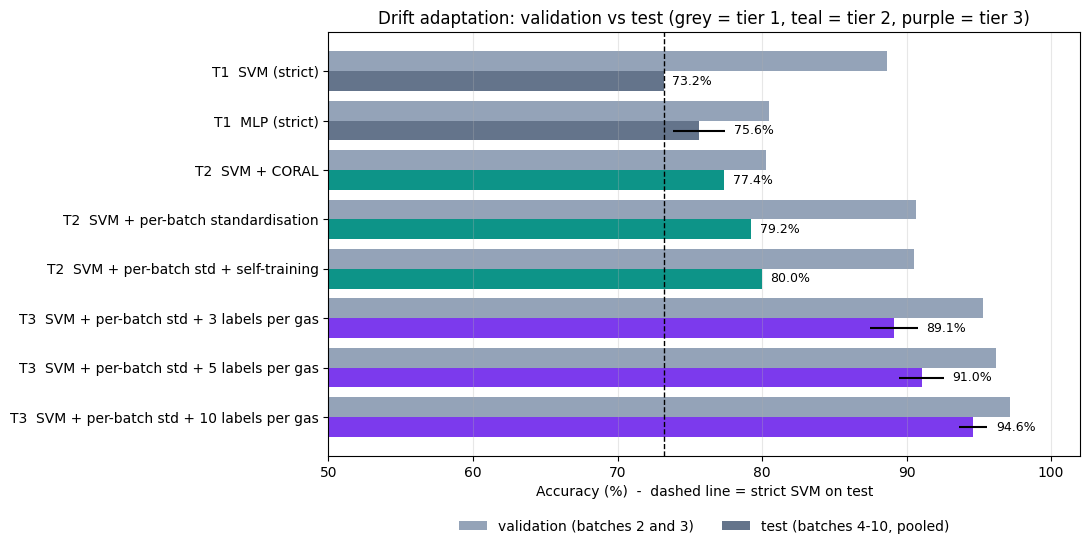

In [3]:
fig, ax = plt.subplots(figsize=(11, 5.6))
y = np.arange(len(METHODS))[::-1]
ax.barh(y + 0.2, summary["validation accuracy %"], height=0.4, color="#94a3b8", label="validation (batches 2 and 3)")
ax.barh(y - 0.2, summary["test accuracy %"], height=0.4, xerr=summary["test std (points)"],
        color=summary["tier"].map({1: "#64748b", 2: "#0d9488", 3: "#7c3aed"}), label="test (batches 4-10, pooled)")
for yi, v, sd in zip(y, summary["test accuracy %"], summary["test std (points)"]):
    ax.text(v + sd + 0.6, yi - 0.2, f"{v:.1f}%", va="center", fontsize=9)
ax.axvline(ref["test accuracy %"], color="black", ls="--", lw=1)
ax.set_yticks(y); ax.set_yticklabels([f"T{t}  {m}" for m, t in summary["tier"].items()])
ax.set_xlim(50, 102); ax.set_xlabel("Accuracy (%)  -  dashed line = strict SVM on test")
ax.set_title("Drift adaptation: validation vs test (grey = tier 1, teal = tier 2, purple = tier 3)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False); ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig("../results/step13_methods.png", dpi=150)
plt.show()

**What to notice:**
- **Per-batch standardisation is the honest winner of tier 2.** It is the only tier-2 method that also beats the strict SVM
  on validation (90.6% vs 88.6%), and on protocol A it lifts the SVM from **73.2% to 79.2% (+6.0 points)** and batch 10
  from 49.6% to 63.3%, without a single test label. The gain is uneven across batches (section 2).
- **Self-training adds little.** On test it reaches 80.0% (+0.7 over per-batch standardisation), but on validation it is
  0.1 points *below* it, so a fair rule would not choose it. Treat it as "about the same".
- **CORAL and the MLP look better on test (77.4% and 75.6%) but worse on validation (80.3% and 80.5% vs 88.6%).**
  Choosing them would be choosing on the test batches, so we do not count them as improvements.
- **A few labels per gas help most:** 3, 5 and 10 labelled recordings per gas per new batch (15-50 per batch) give
  89.1%, 91.0% and 94.6% on the unlabelled rest, with only 1-1.6 points of spread over 10 seeds. That beats protocol C
  (88.6%, which relabels every earlier batch) with far fewer labels.

## 2. Per batch

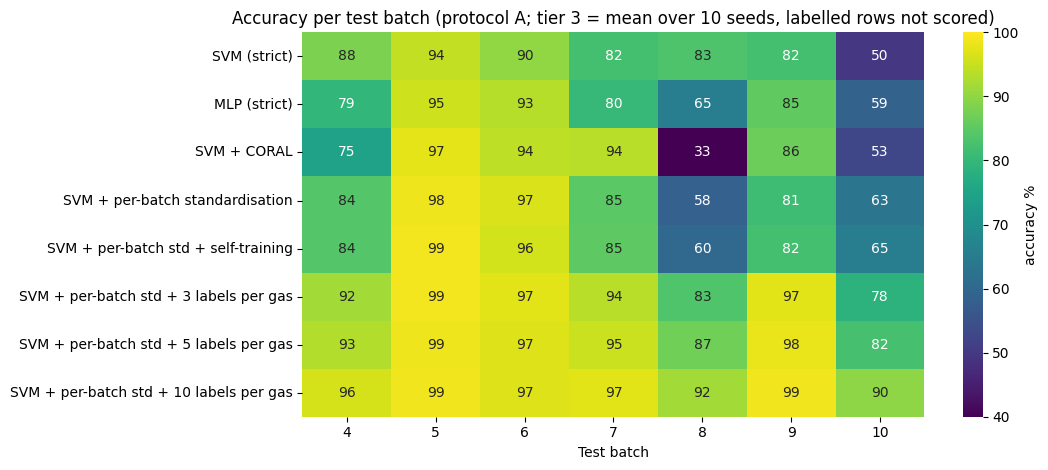

b,4,5,6,7,8,9,10
method,,,,,,,
SVM (strict),0.0,0.0,0.0,0.0,0.0,0.0,0.0
MLP (strict),-8.8,1.0,3.3,-2.0,-18.1,3.2,9.0
SVM + CORAL,-13.7,3.0,3.9,11.4,-50.7,4.3,3.1
SVM + per-batch standardisation,-4.3,4.1,6.6,2.5,-25.0,-0.8,13.7
SVM + per-batch std + self-training,-4.3,4.6,5.8,2.9,-23.2,0.0,15.6
SVM + per-batch std + 3 labels per gas,3.5,4.5,7.3,11.4,0.2,15.2,28.9
SVM + per-batch std + 5 labels per gas,4.8,4.1,6.8,13.1,3.8,16.0,32.7
SVM + per-batch std + 10 labels per gas,8.0,4.2,6.9,15.2,8.4,16.7,40.3


In [4]:
per = A[A["test_batch"] != "pooled"].assign(b=lambda x: x["test_batch"].astype(int))
per_b = per.pivot_table(index="method", columns="b", values="accuracy", aggfunc="mean").loc[METHODS] * 100
fig, ax = plt.subplots(figsize=(11, 4.8))
sns.heatmap(per_b, annot=True, fmt=".0f", cmap="viridis", vmin=40, vmax=100, ax=ax, cbar_kws={"label": "accuracy %"})
ax.set_title("Accuracy per test batch (protocol A; tier 3 = mean over 10 seeds, labelled rows not scored)")
ax.set_xlabel("Test batch"); ax.set_ylabel("")
plt.tight_layout()
plt.savefig("../results/step13_per_batch.png", dpi=150)
plt.show()
(per_b.sub(per_b.loc["SVM (strict)"], axis=1)).round(1)

**What to notice (change in points against the strict SVM, table above):**
- Per-batch standardisation helps most where drift is worst: **batch 10 +13.7** (the largest batch, so it drives the
  pooled gain) and batch 6 +6.6.
- **It badly hurts batch 8 (-25.0 points)** and slightly hurts batch 4 (-4.3). This is the risk the project plan warned
  about: batch 8 is 52% Acetone and batch 4 is 40% Ethanol (Step 2), so their own mean and spread mostly describe one gas,
  and subtracting them removes real gas signal along with the drift. Batch 10 has an even 20% of each gas, which is
  exactly where per-batch scaling works best. Self-training and CORAL show the same pattern.
- **A few labels fix this:** with 3 or more labels per gas, every batch is at or above the strict SVM, and the late
  batches gain the most (batch 10 +29 to +40 points).

## 3. How many labels are worth it?

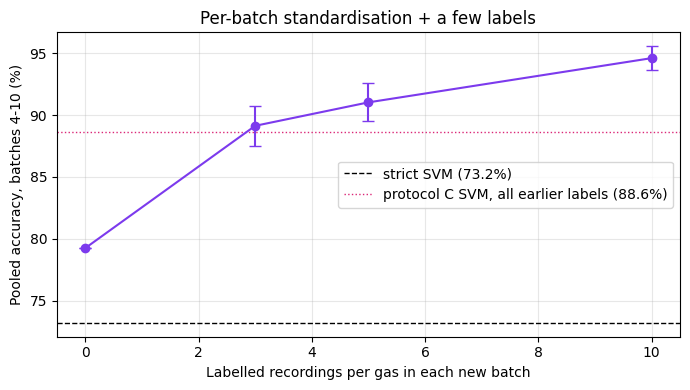

,labels per gas per batch,accuracy %,std
0,0,79.24,0.00
1,3,89.14,1.64
2,5,91.03,1.53
3,10,94.61,0.97


In [5]:
curve = pd.DataFrame({
    "labels per gas per batch": [0, 3, 5, 10],
    "accuracy %": summary.loc[["SVM + per-batch standardisation", "SVM + per-batch std + 3 labels per gas",
                               "SVM + per-batch std + 5 labels per gas", "SVM + per-batch std + 10 labels per gas"],
                              "test accuracy %"].to_numpy(),
    "std": summary.loc[["SVM + per-batch standardisation", "SVM + per-batch std + 3 labels per gas",
                        "SVM + per-batch std + 5 labels per gas", "SVM + per-batch std + 10 labels per gas"],
                       "test std (points)"].to_numpy(),
})
fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(curve["labels per gas per batch"], curve["accuracy %"], yerr=curve["std"], marker="o", color="#7c3aed", capsize=4)
ax.axhline(ref["test accuracy %"], color="black", ls="--", lw=1, label="strict SVM (73.2%)")
ax.axhline(88.6, color="#db2777", ls=":", lw=1, label="protocol C SVM, all earlier labels (88.6%)")
ax.set_xlabel("Labelled recordings per gas in each new batch"); ax.set_ylabel("Pooled accuracy, batches 4-10 (%)")
ax.set_title("Per-batch standardisation + a few labels"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../results/step13_labels_curve.png", dpi=150)
plt.show()
curve.round(2)

## Summary of Step 13
- **Yes, accuracy can be improved, but only by using the new batches.** Under the strict rule nothing beat the tuned
  SVM fairly (the MLP looks better on test but is chosen against by validation).
- **Tier 2 (unlabelled readings):** per-batch standardisation is the fair choice. It wins on validation and lifts the SVM
  from 73.2% to **79.2%** on batches 4-10 (macro-F1 74.5% -> 77.1%). Self-training on top is about the same (80.0% on test,
  slightly lower on validation). CORAL is rejected by validation.
- **Tier 3 (a few labels):** 5 labelled recordings per gas per batch give **91.0%**, and 10 give **94.6%**, scored only on
  the recordings that were not labelled.
- **Limits:** these results use information that protocol A forbids, so they are reported apart from the headline.
  Per-batch standardisation needs a whole batch (or a large enough window) of readings before it can predict, and it
  assumes each batch has a similar mix of gases: on batch 8 (52% Acetone) it loses 25 points. Its pooled gain comes
  mostly from batch 10, which has a perfectly even gas mix. Only the SVM was adapted, with Step 8's settings and no new
  tuning, and the tier-2 methods were run once (they are deterministic with these settings).